# Character-Level CNN for Phishing Detection

COSC 50523 — Deep Minds  
Leiton Peterson

This notebook trains the team's default character-level CNN on raw
URL text using the existing training and validation splits.

Each URL is converted into character IDs. The CNN learns patterns
in those character sequences to predict whether a URL is phishing.

The character vocabulary is built from training URLs only.
Validation data is used for early stopping and evaluation.
No test-set evaluation is performed in this notebook.

Labels:
- 0 = legitimate
- 1 = phishing

This notebook uses the team's shared project_utils.py and
torch_models.py files.

In [1]:
from google.colab import drive
from pathlib import Path
import sys
import torch

drive.mount('/content/drive')

DATA_DIR = Path('/content/drive/MyDrive/DeepMinds')

# Confirm the dataset and shared code are available.
required_files = [
    'master_with_splits.csv',
    'project_utils.py',
    'torch_models.py',
]

for filename in required_files:
    file_path = DATA_DIR / filename
    print(f"{filename}: {'FOUND' if file_path.is_file() else 'MISSING'}")
    assert file_path.is_file(), f"Required file not found: {file_path}"

# Let Python import the shared code from Drive.
sys.path.insert(0, str(DATA_DIR))

print("\nPyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Check the Colab runtime before training.")

Mounted at /content/drive
master_with_splits.csv: FOUND
project_utils.py: FOUND
torch_models.py: FOUND

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:
import project_utils
import torch_models

from project_utils import load_master, evaluate_model, plot_history
from torch_models import (
    DEFAULT_CNN,
    DEVICE,
    fit_char_cnn,
    predict_proba,
    count_params,
)

print("Data helpers:", project_utils.__file__)
print("Model helpers:", torch_models.__file__)
print("Training device:", DEVICE)

print("\nDefault CNN settings:")
for setting, value in DEFAULT_CNN.items():
    print(f"{setting}: {value}")

Data helpers: /content/drive/MyDrive/DeepMinds/project_utils.py
Model helpers: /content/drive/MyDrive/DeepMinds/torch_models.py
Training device: cuda

Default CNN settings:
max_len: 200
embed_dim: 32
filters: 64
kernel_sizes: (3, 5, 7)
dropout: 0.3
hidden: 64
use_conv: True
strip_prefix: False
lr: 0.001
batch_size: 256
max_epochs: 20
patience: 3


## Load the data and train the default CNN

Use the team's existing split assignments. The model receives raw
URL text rather than the 22 numeric features.

The shared helper builds the character vocabulary from training URLs
only and pads or truncates each URL to 200 characters.

Training uses Adam and binary cross-entropy loss, with early stopping
based on validation loss. The best saved epoch's weights are restored.

In [ ]:
import pandas as pd

df = load_master(DATA_DIR)

# Check the columns and split assignments needed by the CNN.
assert {'URL', 'label', 'split'}.issubset(df.columns)
assert df['split'].isin(['train', 'val', 'test']).all()

for split in ['train', 'val']:
    rows = df[df['split'] == split]

    assert len(rows) > 0, f"No rows found for {split}."
    assert set(rows['label'].unique()) == {0, 1}
    assert rows['URL'].map(
        lambda url: isinstance(url, str) and bool(url.strip())
    ).all(), f"Missing or invalid URLs in {split}."

# Show training and validation class counts without printing raw URLs.
summary = pd.crosstab(
    df.loc[df['split'].isin(['train', 'val']), 'split'],
    df.loc[df['split'].isin(['train', 'val']), 'label'],
).rename(columns={0: 'Legitimate', 1: 'Phishing'})

summary['Total'] = summary.sum(axis=1)
display(summary)

print("Data checks passed.")

label,Legitimate,Phishing,Total
split,,,
train,94395,70661,165056
val,20227,15142,35369


Data checks passed.


In [ ]:
# Keep a record of the default settings used for this experiment.
cnn_config = DEFAULT_CNN.copy()

print("Training the default character CNN on:", DEVICE)

model, history, cfg, sequences, vocab = fit_char_cnn(
    df,
    config=cnn_config,
    split_col='split',
    verbose=True,
)

print("\nTraining finished.")
print("Training characters in vocabulary:", len(vocab))
print("Trainable parameters:", count_params(model))
print("Epochs completed:", len(history['loss']))
print("Best epoch restored:", history['best_epoch'])

Training the default character CNN on: cuda
Epoch  1  train loss 0.03663  val loss 0.01266
Epoch  2  train loss 0.01279  val loss 0.01238
Epoch  3  train loss 0.01149  val loss 0.01181
Epoch  4  train loss 0.01076  val loss 0.01283
Epoch  5  train loss 0.01037  val loss 0.01130
Epoch  6  train loss 0.00970  val loss 0.01338
Epoch  7  train loss 0.00884  val loss 0.01200
Epoch  8  train loss 0.00842  val loss 0.01176
Early stopping: no improvement for 3 epochs.

Training finished.
Training characters in vocabulary: 59
Trainable parameters: 45281
Epochs completed: 8
Best epoch restored: 5


## Save the trained model

Save the model weights, character vocabulary, configuration, and
training history to Google Drive so the model can be reused.
These model artifacts should not be committed to GitHub.

In [ ]:
import json

# Save everything needed to reconstruct this trained CNN.
checkpoint_path = DATA_DIR / 'char_cnn_default.pt'

checkpoint = {
    'model_state_dict': {
        name: weights.detach().cpu()
        for name, weights in model.state_dict().items()
    },
    'vocab': vocab,
    'config': cfg,
    'history': history,
    'seed': 42,
    'split_col': 'split',
    'threshold': 0.5,
    'label_mapping': {'legitimate': 0, 'phishing': 1},
}
checkpoint['state_dict'] = checkpoint['model_state_dict']
torch.save(checkpoint, checkpoint_path)

# Also save readable copies of the settings and training history.
with open(DATA_DIR / 'char_cnn_default_config.json', 'w') as file:
    json.dump(cfg, file, indent=2)

with open(DATA_DIR / 'history_cnn.json', 'w') as file:
    json.dump(history, file, indent=2)

print("Saved:", checkpoint_path)
print("File size:", checkpoint_path.stat().st_size, "bytes")

Saved: /content/drive/MyDrive/DeepMinds/char_cnn_default.pt
File size: 186715 bytes


## Validation evaluation

Evaluate the restored best-epoch model using a phishing probability
threshold of 0.5. The test split is not evaluated.

   Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
Char-CNN   val    0.9981     0.9999  0.9956 0.9978   0.9988   0.999                1               66


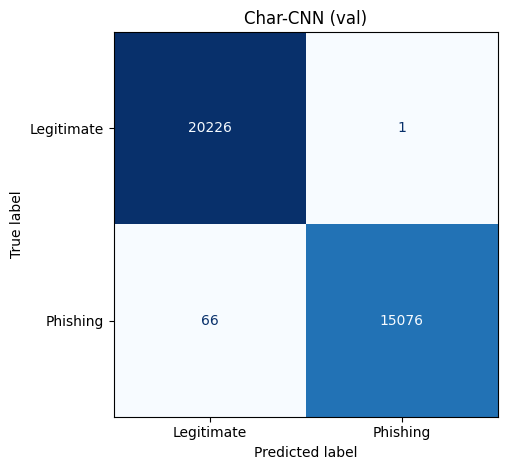

In [ ]:
FIG_DIR = DATA_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)

X_val_ids, y_val = sequences['val']

# Character IDs must be integers, so use torch.long.
val_probabilities = predict_proba(
    model,
    X_val_ids,
    x_dtype=torch.long,
)

cnn_results = evaluate_model(
    name='Char-CNN',
    split='val',
    y_true=y_val,
    y_prob=val_probabilities,
    threshold=0.5,
    save_path=FIG_DIR / 'cm_char_cnn_default_val.png',
)

# Save the actual evaluation results as a small table.
pd.DataFrame([cnn_results]).to_csv(
    DATA_DIR / 'char_cnn_default_val_results.csv',
    index=False,
)

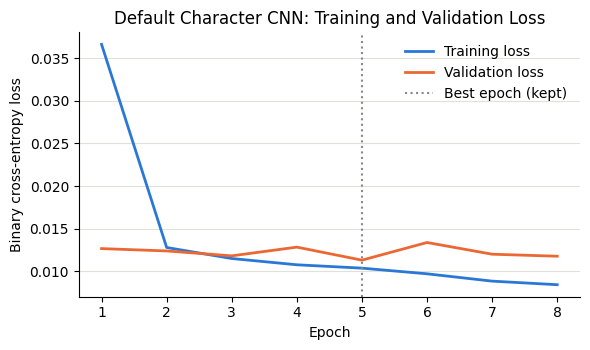

In [ ]:
plot_history(
    history,
    title='Default Character CNN: Training and Validation Loss',
    save_path=FIG_DIR / 'loss_char_cnn_default.png',
)

## Verify the saved checkpoint

In [ ]:
import numpy as np
from torch_models import CharCNN
from project_utils import encode_urls, strip_prefix

saved = torch.load(
    checkpoint_path,
    map_location='cpu',
    weights_only=True,
)
saved_cfg = saved['config']

# Reconstruct the architecture using the saved settings.
restored_model = CharCNN(
    vocab_size=len(saved['vocab']) + 2,
    embed_dim=saved_cfg['embed_dim'],
    filters=saved_cfg['filters'],
    kernel_sizes=saved_cfg['kernel_sizes'],
    dropout=saved_cfg['dropout'],
    hidden=saved_cfg['hidden'],
    use_conv=saved_cfg['use_conv'],
).to(DEVICE)

restored_model.load_state_dict(saved['state_dict'])

# Encode a small validation sample using the SAVED vocabulary.
sample_urls = df.loc[df['split'] == 'val', 'URL'].head(128).tolist()

if saved_cfg['strip_prefix']:
    sample_urls = [strip_prefix(url) for url in sample_urls]

sample_ids = encode_urls(
    sample_urls,
    saved['vocab'],
    saved_cfg['max_len'],
)

restored_probs = predict_proba(
    restored_model,
    sample_ids,
    x_dtype=torch.long,
)

np.testing.assert_allclose(
    restored_probs,
    val_probabilities[:len(sample_urls)],
    rtol=1e-5,
    atol=1e-6,
)

print("Checkpoint reload passed: predictions match on 128 validation URLs.")

Checkpoint reload passed: predictions match on 128 validation URLs.


In [ ]:
from project_utils import log_result

LOG = DATA_DIR / 'results_log.csv'

# Identify this saved checkpoint so rerunning this cell won't log it twice.
run_id = f"char_cnn_default_{checkpoint_path.stat().st_mtime_ns}"

already_logged = False
if LOG.exists():
    existing = pd.read_csv(LOG)
    if 'hp_run_id' in existing.columns:
        already_logged = existing['hp_run_id'].astype(str).eq(run_id).any()

if already_logged:
    print("This checkpoint's results are already logged.")
else:
    log_result(
        cnn_results,
        {
            'run_id': run_id,
            'family': 'CNN',
            'experiment': 'main',
            'features': 'raw URL',
            'split_col': 'split',
            'seed': 42,
            'threshold': 0.5,
            'params': count_params(model),
            'best_epoch': history['best_epoch'],
            'epochs_completed': len(history['loss']),
            'checkpoint': checkpoint_path.name,
            **cfg,
        },
        LOG,
    )
    print("Added this experiment to:", LOG)

Added this experiment to: /content/drive/MyDrive/DeepMinds/results_log.csv


## Preliminary findings and handoff

The default character CNN achieved approximately 99.81% validation
accuracy and 99.56% phishing recall, with 66 false negatives and
1 false positive across 35,369 validation examples.

Training stopped after 8 epochs and restored the weights from epoch 5.
Training loss continued decreasing while validation loss fluctuated,
supporting the use of early stopping.

These results describe one configuration and one random seed.
They do not establish performance on unseen domains or future phishing
websites. No test-set evaluation was performed.

The checkpoint is saved in DeepMinds/char_cnn_default.pt on shared
Google Drive. It contains both state_dict and model_state_dict,
plus vocab, config, history, and label information.

Training history is also saved as history_cnn.json for the team's
figure scripts. The compatibility repair verified that the saved
model weights were unchanged.

In [2]:
import json
import os
import shutil
from datetime import datetime

import pandas as pd
import torch

stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
checkpoint_path = DATA_DIR / 'char_cnn_default.pt'

# Read the existing trained model; no training happens here.
saved = torch.load(
    checkpoint_path,
    map_location='cpu',
    weights_only=True,
)

assert 'history' in saved, "Checkpoint is missing training history."

# Add the key expected by the team's later notebooks.
if 'state_dict' not in saved:
    assert 'model_state_dict' in saved, "No model weights found."

    backup = DATA_DIR / f'char_cnn_default_before_fix_{stamp}.pt'
    shutil.copy2(checkpoint_path, backup)

    original_times = checkpoint_path.stat()
    saved['state_dict'] = saved['model_state_dict']
    torch.save(saved, checkpoint_path)

    # Preserve the modification time used by our original run ID.
    os.utime(
        checkpoint_path,
        ns=(original_times.st_atime_ns, original_times.st_mtime_ns),
    )
    print("Added state_dict; original checkpoint backed up.")
else:
    print("state_dict already exists.")

# Save the history under the filename expected by the team.
history_path = DATA_DIR / 'history_cnn.json'
if history_path.exists():
    shutil.copy2(
        history_path,
        DATA_DIR / f'history_cnn_before_fix_{stamp}.json',
    )

with open(history_path, 'w') as file:
    json.dump(saved['history'], file, indent=2)

print("Saved history_cnn.json.")

# Normalize only the CNN rows with our old feature label.
log_path = DATA_DIR / 'results_log.csv'
log = pd.read_csv(log_path)

mask = (
    log['hp_family'].eq('CNN')
    & log['hp_features'].eq('raw_url')
)

if mask.any():
    shutil.copy2(
        log_path,
        DATA_DIR / f'results_log_before_fix_{stamp}.csv',
    )

    log.loc[mask, 'hp_features'] = 'raw URL'
    log.to_csv(log_path, index=False)

print("CNN log rows renamed:", int(mask.sum()))

# Confirm both checkpoint keys contain identical weights.
checked = torch.load(
    checkpoint_path,
    map_location='cpu',
    weights_only=True,
)

assert checked['state_dict'].keys() == checked['model_state_dict'].keys()
assert all(
    torch.equal(checked['state_dict'][key],
                checked['model_state_dict'][key])
    for key in checked['state_dict']
)

print("Compatibility fixes complete. Model weights are unchanged.")

Added state_dict; original checkpoint backed up.
Saved history_cnn.json.
CNN log rows renamed: 1
Compatibility fixes complete. Model weights are unchanged.
